# 第 8 堂：機器學習流程
LESSON 08 · MACHINE LEARNING WORKFLOW

### 本堂學習目標
學完後，你應該能夠：
1. 說出機器學習從「拿到資料」到「做出預測」的完整步驟。
2. 理解為什麼要把資料分成**訓練集**和**測試集**。
3. 正確準備特徵 `X`（二維）和標籤 `y`（一維）。
4. 使用 `train_test_split()` 切分資料。
5. 用 `fit()` 訓練模型、用 `predict()` 預測、用 `score()` 初步評估。
6. 把第 1～7 堂學的工具全部串起來，完成第一個完整的機器學習小專案。

### 本堂上課順序
| 順序 | 內容 |
| :--- | :--- |
| 1. 生活例子 | 為什麼考試不能考練習題？ |
| 2. 概念解說 | 機器學習流程九步驟、訓練集與測試集 |
| 3. 程式教學 | 用房屋資料，從頭走完九個步驟 |
| 4. 逐行解析 | 每段程式後面都有解析表 |
| 5. 實際練習 | 4 個練習，附參考解答 |
| 6. 小考驗收 | 自我檢查，再回對話做小考 |

---
## 一、生活例子：為什麼考試不能考練習題？

假設老師給你 100 題數學練習題，讓你回家練習。

**情況 A：** 期末考的題目，跟練習題**一模一樣**。
你只要把答案背起來，就能考 100 分。
但這代表你真的學會數學了嗎？**不一定。** 你可能只是背答案。

**情況 B：** 期末考的題目是**沒看過的新題目**。
如果你還是考很高分，代表你真的理解了解題方法。

機器學習也是一樣：

| 學生 | 機器學習 |
| :--- | :--- |
| 練習題 | **訓練集**（Training Set）：給模型學習用的資料 |
| 期末考題 | **測試集**（Test Set）：模型「沒看過」的資料，用來檢查它學得好不好 |
| 讀書 | `fit()`：訓練 |
| 考試作答 | `predict()`：預測 |
| 考卷分數 | `score()`：評估 |

> 我們真正在乎的，不是模型對「看過的資料」答得好不好，而是它對「**沒看過的新資料**」能不能預測準確。
> 這個能力叫做**泛化能力**（Generalization），第 12 堂會再深入介紹。

所以在訓練之前，要先把資料切成兩份：一份給模型讀書，另一份**藏起來**，等模型訓練完再拿來考它。

---
## 二、概念解說

### 1. 機器學習的完整流程（九步驟）

| 步驟 | 要做什麼 | 用到的工具 | 第幾堂學過 |
| :--- | :--- | :--- | :--- |
| ① 讀取資料 | 把 CSV 讀進來 | `pd.read_csv()` | 第 5 堂 |
| ② 認識資料 | 看內容、型態、缺失、統計 | `head()`、`info()`、`describe()` | 第 5 堂 |
| ③ 清理資料 | 轉型態、處理缺失和重複 | `to_numeric()`、`dropna()`、`fillna()`、`drop_duplicates()` | 第 6 堂 |
| ④ 畫圖觀察 | 看特徵和標籤有沒有關係 | `plt.scatter()` | 第 7 堂 |
| ⑤ 準備 X 和 y | 決定特徵和標籤 | `df[[...]]`、`df[...]` | 第 1、5 堂 |
| ⑥ 切分資料 | 分成訓練集和測試集 | `train_test_split()` | **本堂新教** |
| ⑦ 訓練模型 | 讓模型從訓練集學習 | `fit()` | 第 2 堂 |
| ⑧ 預測 | 用測試集考模型 | `predict()` | 第 2 堂 |
| ⑨ 評估 | 看預測得準不準 | `score()`、計算誤差 | **本堂新教** |

你會發現：**九個步驟中，只有兩個是新的。** 其他都是前面七堂學過的工具。
這就是為什麼第一階段要花六堂課打好資料處理的基礎。

①～④ 合起來叫做**資料前處理**（Data Preprocessing）。實務上，資料科學家大約有一大半的時間都花在這幾步。

### 2. X 和 y 的形狀規則（很重要！）

| 名稱 | 意思 | 形狀 | 怎麼取 |
| :--- | :--- | :--- | :--- |
| `X`（大寫） | 特徵，可以有很多個 | **二維**（列, 欄） | `df[["坪數", "屋齡"]]`（**兩層**中括號） |
| `y`（小寫） | 標籤，只有一個 | **一維**（列,） | `df["房價"]`（**一層**中括號） |

記憶方式：**大寫 X 是一張表，小寫 y 是一欄。**

這裡會用到第 3～5 堂「中括號有幾層」的觀念：
- `df[["坪數"]]` → 兩層 → DataFrame → 二維 → shape `(列數, 1)` ✓ 可以當 X
- `df["坪數"]` → 一層 → Series → 一維 → shape `(列數,)` ✗ 當 X 會出錯

就算只有一個特徵，X 也必須是二維的。第 2 堂的 `X = [[20], [30], [40], [50]]` 用了兩層中括號，就是這個原因。

### 3. 切分資料的四個結果

```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
```

| 名稱 | 內容 | 給誰用 |
| :--- | :--- | :--- |
| `X_train` | 訓練用的特徵（練習題的題目） | `fit()` |
| `y_train` | 訓練用的標籤（練習題的答案） | `fit()` |
| `X_test` | 測試用的特徵（考卷題目） | `predict()` |
| `y_test` | 測試用的標籤（考卷答案，**先藏起來**） | 評估時才拿出來對答案 |

| 參數 | 意思 |
| :--- | :--- |
| `test_size=0.2` | 拿 20% 的資料當測試集，剩下 80% 當訓練集 |
| `random_state=42` | 固定「隨機洗牌」的方式，讓每次執行切出來的結果都一樣（42 只是慣例，任何整數都可以） |

---
## 三、程式教學：房價預測小專案

我們要用「坪數」和「屋齡」兩個特徵，預測「房價」。

### 步驟 0：匯入工具

In [5]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------- ----------------------- 3.4/8.4 MB 22.3 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 17.3 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 16.5 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---- ----------------------------------- 3.9/37.4 MB 19.7 MB/s eta 0:00:02
   -------- ------------------------------- 7.9/37.4 MB 19.9 MB/s eta 0:00:02
   ------------- -------------------------- 12.3/37.4 MB 20.1 MB/s eta 0:00:02
   ----------------- ---------------------- 16.8/37.4 MB 20.3 MB/s eta 0:00:02
   ---------------------- ----------------- 21.2/37.4 MB 20.5 MB/s eta 0:00:01
   --------------------------- ------------ 25.4/37.4 MB 20.7 MB/s eta 0:00:01
   ----------------------------- ---------- 27.3/37.4 MB 20.7 MB/s eta 0:00:01
   ----------------------------- ---------- 27.3/37.4 MB 20.7 MB/s eta 0:00:01
   

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 中文字型設定（同第 7 堂步驟 0）
import sys, os
import matplotlib.font_manager as fm
if "google.colab" in sys.modules:
    os.system("apt-get -qq install -y fonts-noto-cjk > /dev/null")
noto = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if os.path.exists(noto):
    fm.fontManager.addfont(noto)
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "Microsoft JhengHei", "PingFang TC", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("工具匯入完成")

工具匯入完成


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `import pandas as pd` 等三行 | 第 3～7 堂學過的三個工具箱 |
| `from sklearn.model_selection import train_test_split` | **新的**：從 sklearn 的「模型選擇」工具中，匯入切分資料的函式 |
| `from sklearn.linear_model import LinearRegression` | 第 2 堂學過的線性迴歸模型 |
| 字型設定 | 和第 7 堂一樣，讓圖上的中文正常顯示 |

### 步驟 ①：讀取資料

實務上資料會是一個 CSV 檔。這裡先用程式**產生** `house.csv`，再用 `pd.read_csv()` 讀進來，模擬真實情況。

注意這份資料是**故意弄髒的**，等一下要清理。

In [7]:
# 產生一份房屋資料，存成 house.csv（模擬主管給你的檔案）
raw = pd.DataFrame({
    "坪數": [43, 26, 59, 58, 17, 23, 24, 23, 41, 31, 37, 25, 58, 45, 45, 20, 22, 56, 29, 54,
             51, 15, 36, 39, 36, 19, 48, 26, 31, 34, 28, 35, 53, 36, 49, 57, 25, 26, 40, 23, 43],
    "屋齡": [28, 27, 28, 38, "未知", 37, 40, 36, 13, 3, 35, 38, 14, 26, 7, 35, 34, 17, 32, 9,
             39, 32, 33, 27, 2, 32, 29, 9, 35, 6, 16, 31, 31, 1, 11, 38, 23, 6, 14, 25, 28],
    "房價": [1069, 608, 1494, 1340, 516, 507, 462, 400, 1105, np.nan, 828, 541, 1582, 1093, 1324, 493, 527, 1516, 718, 1579,
             1171, 319, 863, 918, 1014, 379, 1185, 799, 626, 917, 758, 819, 1275, 1122, 1392, 1331, 669, 753, 1035, 586, 1069]
})
raw.to_csv("house.csv", index=False)

# ① 讀取資料
df = pd.read_csv("house.csv")
print("資料讀取完成")

資料讀取完成


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `raw.to_csv("house.csv", index=False)` | 把資料存成 CSV（第 6 堂），`index=False` 不存索引 |
| `pd.read_csv("house.csv")` | 讀取 CSV（第 5 堂） |

故意埋的三個問題：屋齡有一格是文字「未知」、房價有一格是 NaN、最後一列和第一列完全重複。看看你能不能在步驟 ② 找到它們。

### 步驟 ②：認識資料

In [8]:
print(df.head())
print("-" * 30)
print(df.shape)
print("-" * 30)
df.info()

   坪數  屋齡      房價
0  43  28  1069.0
1  26  27   608.0
2  59  28  1494.0
3  58  38  1340.0
4  17  未知   516.0
------------------------------
(41, 3)
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   坪數      41 non-null     int64  
 1   屋齡      41 non-null     str    
 2   房價      40 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 1.1 KB


#### 逐行解析與觀察

| 程式碼 | 看到什麼 |
| :--- | :--- |
| `df.head()` | 前 5 筆。第 5 列（索引 4）的屋齡是「未知」 |
| `df.shape` | `(41, 3)`：41 筆資料、3 個欄位 |
| `df.info()` | 房價的 Non-Null Count 是 **40**，比 41 少 1 → 有 1 個缺失值 |
| | 屋齡的 Dtype **不是數字**（顯示 object 或 str）→ 裡面混了文字 |

這就是 `info()` 的用處：一次看出「缺失」和「型態」兩種問題。

老師提醒：`info()` 看不出「未知」有幾個，也看不出重複資料。這些要在步驟 ③ 一個一個檢查。

### 步驟 ③：清理資料

照第 2 回複習卷學到的順序：**轉型態 → 查缺失 → 刪重複 → 處理缺失**。

In [9]:
# ③-1 轉型態：把屋齡轉成數字，「未知」會變成 NaN
df["屋齡"] = pd.to_numeric(df["屋齡"], errors="coerce")

# ③-2 查缺失
print("缺失值數量：")
print(df.isnull().sum())

# ③-3 查重複、刪重複（記得要用 df = 存回去！）
print("重複資料筆數：", df.duplicated().sum())
df = df.drop_duplicates()
print("刪除重複後：", df.shape)

缺失值數量：
坪數    0
屋齡    1
房價    1
dtype: int64
重複資料筆數： 1
刪除重複後： (40, 3)


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `pd.to_numeric(..., errors="coerce")` | 轉成數字，轉不動的「未知」變成 NaN |
| `df.isnull().sum()` | 每一欄有幾個缺失值：屋齡 1（原本的「未知」）、房價 1 |
| `df.duplicated().sum()` | 有幾列是重複的：1 列 |
| `df = df.drop_duplicates()` | 刪除重複，**有 `df =` 才算數** |

刪除重複後剩 40 列。接下來處理兩個缺失值，但這兩個缺失值的**處理方式不一樣**。

#### 重要觀念：標籤缺失要刪，特徵缺失可以補

| 缺的是什麼 | 例子 | 怎麼處理 | 原因 |
| :--- | :--- | :--- | :--- |
| **標籤 y** | 房價是 NaN | **刪除整列** | 房價就是「正確答案」。沒有答案的題目，不能拿來讓模型學習；如果用平均值補，等於自己編一個假答案教模型 |
| **特徵 X** | 屋齡是 NaN | **可以填補** | 其他欄位（坪數、房價）還是有用的資訊，用中位數或平均數補一個合理的值，就能保留這筆資料 |

只刪除「房價」欄有缺失的列，要用 `dropna(subset=["房價"])`：
- `subset` 的意思是「只看這幾欄」。
- 不寫 `subset` 的話，屋齡缺失的那一列也會一起被刪掉。

In [10]:
# ③-4 標籤缺失 → 刪除（只看房價欄）
df = df.dropna(subset=["房價"])

# ③-5 特徵缺失 → 用中位數填補
df["屋齡"] = df["屋齡"].fillna(df["屋齡"].median())

print("清理完成後：", df.shape)
print(df.isnull().sum())

清理完成後： (39, 3)
坪數    0
屋齡    0
房價    0
dtype: int64


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `df.dropna(subset=["房價"])` | 只要「房價」是 NaN 就刪掉那一列 |
| `df["屋齡"].median()` | 屋齡的中位數（第 6 堂提過的另一種填補方式） |
| `fillna(...)` | 把屋齡的 NaN 補上中位數 |

清理完剩 39 筆，而且沒有任何缺失值了。

**為什麼這裡用中位數，不用平均數？**
中位數比較不會被極端值影響。例如有一間 100 年的古厝，平均數會被拉高，中位數幾乎不受影響。兩種都可以用，這裡示範第二種方法。

### 步驟 ④：畫圖觀察

在訓練之前，先看看特徵和房價有沒有關係（第 7 堂：散佈看關係）。

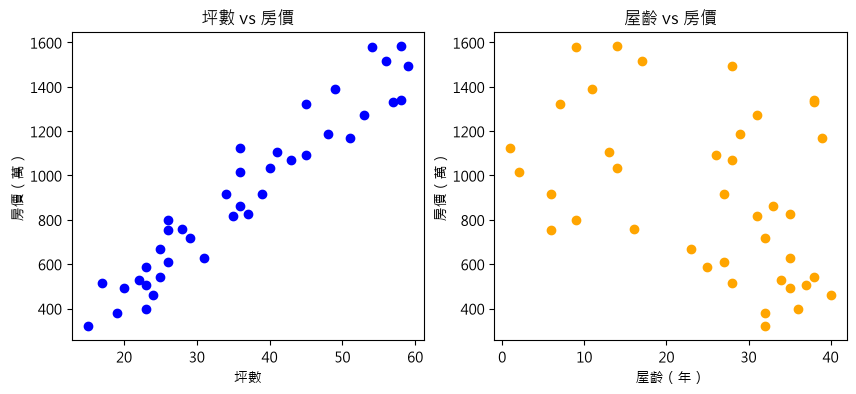

In [11]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(df["坪數"], df["房價"], color="blue")
plt.title("坪數 vs 房價")
plt.xlabel("坪數")
plt.ylabel("房價（萬）")

plt.subplot(1, 2, 2)
plt.scatter(df["屋齡"], df["房價"], color="orange")
plt.title("屋齡 vs 房價")
plt.xlabel("屋齡（年）")
plt.ylabel("房價（萬）")

plt.show()

#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `plt.figure(figsize=(10, 4))` | 開一張寬 10、高 4 的畫布（比較寬，才放得下兩張圖） |
| `plt.subplot(1, 2, 1)` | 把畫布切成 1 列 2 欄，現在畫第 1 格（左邊） |
| `plt.subplot(1, 2, 2)` | 現在畫第 2 格（右邊） |

`subplot` 是新指令，只要知道「可以把兩張圖並排」就好，之後會常常用到。

#### 從圖可以看到
- **左圖：** 點排成一條明顯往右上的線 → 坪數越大，房價越高（強烈的正相關）。
- **右圖：** 點比較散，但大致往右下 → 屋齡越大，房價稍微低一點（較弱的負相關）。
- 兩張圖都沒有特別離群的點 → 不用處理異常值。

結論：坪數和屋齡都和房價有關，可以拿來當特徵。

### 步驟 ⑤：準備 X 和 y

In [12]:
X = df[["坪數", "屋齡"]]   # 特徵：兩層中括號 → DataFrame（二維）
y = df["房價"]             # 標籤：一層中括號 → Series（一維）

print("X 的 shape：", X.shape)
print("y 的 shape：", y.shape)

X 的 shape： (39, 2)
y 的 shape： (39,)


#### 逐行解析

| 程式碼 | 結果 | 意思 |
| :--- | :--- | :--- |
| `df[["坪數", "屋齡"]]` | `(39, 2)` | 39 間房子、每間 2 個特徵（二維） |
| `df["房價"]` | `(39,)` | 39 個答案（一維） |

**檢查重點：X 和 y 的第一個數字（列數）一定要一樣。** 每一間房子的特徵，都要對應到一個答案。這和第 7 堂「x 和 y 數量要一樣」是同一個道理。

#### 如果 X 只用一層中括號會怎樣？

In [13]:
X_wrong = df["坪數"]   # 一層中括號 → 一維
print("X_wrong 的 shape：", X_wrong.shape)

try:
    LinearRegression().fit(X_wrong, y)
except ValueError as e:
    print("出現錯誤：", str(e)[:85])

X_wrong 的 shape： (39,)
出現錯誤： Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a Da


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `df["坪數"]` | 一層中括號，得到一維的 Series，shape 是 `(39,)` |
| `try: ... except ValueError as e:` | 「試著執行，如果出錯就印出錯誤訊息，而不是讓程式停掉」。這是為了示範錯誤才用的，平常不用寫 |

錯誤訊息會是下面其中一種（依 sklearn 版本不同）：
- `Expected 2D array, got 1D array instead`
- `Expected a 2-dimensional container but got <class 'pandas.Series'> instead`

兩種意思都一樣：**需要二維，卻拿到一維**。

**以後看到這種錯誤，第一件事就是檢查 X 是不是少了一層中括號。** 改成 `df[["坪數"]]` 就好了。

### 步驟 ⑥：切分訓練集與測試集（本堂新教）

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train：", X_train.shape)
print("X_test ：", X_test.shape)
print("y_train：", y_train.shape)
print("y_test ：", y_test.shape)

X_train： (31, 2)
X_test ： (8, 2)
y_train： (31,)
y_test ： (8,)


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `train_test_split(X, y, ...)` | 把 X 和 y **一起**洗牌、再切開，確保每間房子的特徵和答案不會被拆散 |
| `test_size=0.2` | 20% 當測試集 |
| `random_state=42` | 固定洗牌方式，每次執行結果一樣 |
| `X_train, X_test, y_train, y_test =` | 一次接住四個結果，**順序固定**：先 X 的兩個，再 y 的兩個；每組都是先 train 後 test |

#### 結果怎麼看
- 39 筆的 20% 是 7.8，sklearn 會**無條件進位**成 8 筆當測試集，剩下 31 筆當訓練集。
- X_train `(31, 2)` 和 y_train `(31,)` 的列數一樣；X_test `(8, 2)` 和 y_test `(8,)` 也一樣。

#### 為什麼要洗牌？
如果資料是照時間排的（例如前面都是舊房子、後面都是新房子），直接切最後 20% 當測試集，測試集就會全部都是新房子，考試範圍不公平。洗牌可以讓訓練集和測試集都有各種房子。

### 步驟 ⑦：訓練模型

In [15]:
model = LinearRegression()
model.fit(X_train, y_train)

print("訓練完成！")

訓練完成！


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `LinearRegression()` | 建立一個空的模型（還沒讀過書） |
| `model.fit(X_train, y_train)` | 用**訓練集**讓模型讀書。注意：**只給 train，不給 test** |

和第 2 堂唯一的差別：以前把全部資料都給 `fit()`，現在只給 80% 的訓練集。另外 20% 藏起來，等一下考試用。

### 步驟 ⑧：預測（考試作答）

In [16]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    "坪數": X_test["坪數"],
    "屋齡": X_test["屋齡"],
    "實際房價": y_test,
    "預測房價": y_pred.round(0),
})
result["差距"] = (result["預測房價"] - result["實際房價"]).round(0)
print(result)

    坪數    屋齡    實際房價    預測房價     差距
34  49  11.0  1392.0  1340.0  -52.0
37  26   6.0   753.0   785.0   32.0
4   17  28.0   516.0   392.0 -124.0
14  45   7.0  1324.0  1267.0  -57.0
31  35  31.0   819.0   833.0   14.0
27  26   9.0   799.0   763.0  -36.0
6   24  40.0   462.0   484.0   22.0
28  31  35.0   626.0   700.0   74.0


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `model.predict(X_test)` | 把考卷題目（X_test）交給模型作答，得到預測結果 |
| `y_pred` | pred = prediction，預測值。慣例上預測的答案都叫 `y_pred` |
| `pd.DataFrame({...})` | 把題目、正確答案、模型答案排成一張表，方便對照 |
| `y_pred.round(0)` | 四捨五入到整數 |
| `result["差距"] = ...` | 新增一欄：預測 − 實際。正數代表猜太高，負數代表猜太低 |

左邊的索引不是 0、1、2、3…，因為洗牌後，測試集保留了它們**原本在 df 裡的索引**。

從表格可以看到，大部分的預測和實際房價只差幾十萬，對一間上千萬的房子來說算是相當接近。

**請注意索引 4 那一列：** 它差了一百多萬，是誤差最大的一間。它就是步驟 ③ 裡屋齡原本寫「未知」、被我們補成中位數的那間房子！
補上的值只是「合理的猜測」，不一定是真的屋齡，所以模型對它的預測也比較不準。這說明了**資料清理的品質會直接影響模型的表現**。

### 步驟 ⑨：評估（打分數）

In [17]:
# 方法一：平均差多少（平均絕對誤差，用第 4、5 堂學過的工具就能算）
error = (y_test - y_pred).abs().mean()
print("平均每間房子預測差距：", round(error, 1), "萬")

# 方法二：sklearn 內建的 score()
print("測試集分數 score：", round(model.score(X_test, y_test), 3))

平均每間房子預測差距： 51.4 萬
測試集分數 score： 0.964


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `y_test - y_pred` | 每一間房子的差距（有正有負） |
| `.abs()` | 取絕對值，把負號拿掉（猜低 30 萬和猜高 30 萬都算差 30 萬） |
| `.mean()` | 平均起來，也就是平均每間差多少 |
| `model.score(X_test, y_test)` | 讓模型自己作答 X_test，再跟 y_test 對答案，給出一個分數 |

#### score() 的分數怎麼看？
線性迴歸的 `score()` 叫做 **R²**（R 平方）。現在只要記住：

| 分數 | 意思 |
| :--- | :--- |
| 接近 **1** | 預測得很準 |
| 接近 **0** | 跟「每間都猜平均房價」差不多，等於沒學到東西 |
| **負數** | 比猜平均還差 |

這裡的分數接近 1，代表模型對「沒看過的房子」也預測得很好。更多評估方式會在第 11 堂學。

### 補充實驗：如果拿訓練集來考試會怎樣？

In [18]:
print("訓練集分數（考練習題）：", round(model.score(X_train, y_train), 3))
print("測試集分數（考新題目）：", round(model.score(X_test, y_test), 3))

訓練集分數（考練習題）： 0.987
測試集分數（考新題目）： 0.964


#### 觀察
這次兩個分數都很高，差距不大，代表模型**真的學到了**坪數、屋齡和房價的關係，而不是只把答案背起來。

但在比較複雜的模型上（第 10 堂的決策樹），常常會出現「訓練集 1.0 分、測試集只有 0.6 分」的情況。這就是情況 A 的「背答案」，叫做**過度擬合**（Overfitting），是第 12 堂的主題。

> 這就是為什麼一定要切測試集：**只看訓練集分數，你永遠不知道模型是真的懂，還是在背答案。**

### 步驟 ⑩：用模型預測一間新房子

模型訓練好之後，就可以拿來預測從來沒出現過的房子。

In [19]:
new_house = pd.DataFrame({"坪數": [35], "屋齡": [10]})
print(new_house)

price = model.predict(new_house)
print("預測房價：", price.round(0), "萬")

   坪數  屋齡
0  35  10
預測房價： [987.] 萬


#### 逐行解析

| 程式碼 | 意思 |
| :--- | :--- |
| `pd.DataFrame({"坪數": [35], "屋齡": [10]})` | 一間 35 坪、10 年的新房子。**欄位名稱和順序要跟訓練時的 X 一樣** |
| `model.predict(new_house)` | 預測它的房價 |

這裡用 DataFrame 而不是 `[[35, 10]]`，是因為訓練時的 X 有欄位名稱，預測時也給欄位名稱，sklearn 才不會跳出警告，也比較不會把坪數和屋齡的順序弄反。

---
## 四、本堂重點整理

### 完整流程程式碼（以後可以直接當範本）
```python
df = pd.read_csv("檔名.csv")                       # ① 讀取
df.info()                                          # ② 認識
df = df.drop_duplicates()                          # ③ 清理（依資料狀況調整）
plt.scatter(df["特徵"], df["標籤"])                # ④ 畫圖
X = df[["特徵1", "特徵2"]]                         # ⑤ X 兩層中括號
y = df["標籤"]                                     #    y 一層中括號
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # ⑥ 切分
model = LinearRegression()
model.fit(X_train, y_train)                        # ⑦ 訓練（只用 train）
y_pred = model.predict(X_test)                     # ⑧ 預測（用 test）
model.score(X_test, y_test)                        # ⑨ 評估
```

### 新名詞
| 英文 | 中文 | 白話 |
| :--- | :--- | :--- |
| Data Preprocessing | 資料前處理 | 讀取、認識、清理、畫圖 |
| Training Set | 訓練集 | 練習題 |
| Test Set | 測試集 | 期末考題 |
| `train_test_split` | 切分資料 | 把練習題和考題分開 |
| `test_size` | 測試集比例 | 0.2 = 20% |
| `random_state` | 隨機種子 | 讓每次洗牌結果一樣 |
| `y_pred` | 預測值 | 模型的答案 |
| `score()` / R² | 分數 | 越接近 1 越準 |
| Generalization | 泛化能力 | 對新資料也預測得準 |

### 常見錯誤
| 狀況 | 原因 | 解法 |
| :--- | :--- | :--- |
| `Expected 2D array` 或 `Expected a 2-dimensional container` | X 只用一層中括號 | 改成 `df[["欄位"]]` |
| `Found input variables with inconsistent numbers of samples` | X 和 y 的列數不一樣 | 清理時 X 和 y 要一起處理，最後檢查 shape |
| 每次執行分數都不一樣 | 沒寫 `random_state` | 加上 `random_state=42` |
| 測試集分數很高，但實際上不準 | 不小心把測試集拿去 `fit()` | `fit()` 只能放 `X_train, y_train` |
| `Input X contains NaN` | 還有缺失值沒處理 | 回到步驟 ③ 用 `isnull().sum()` 檢查 |

---
## 五、實際練習

### 練習一：改變測試集比例
把 `test_size` 改成 `0.3`，印出四個結果的 shape。
先預測看看：39 筆的 30% 是 11.7，測試集會有幾筆？

In [ ]:
# 練習一：在這裡寫你的程式

In [ ]:
# 練習一 參考解答
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train2.shape, X_test2.shape, y_train2.shape, y_test2.shape)
# 11.7 無條件進位 → 測試集 12 筆，訓練集 27 筆

### 練習二：只用坪數一個特徵
只用「坪數」當特徵，重新切分、訓練、評估，看看分數和兩個特徵比起來是高還是低。
提示：X 要用幾層中括號？

In [ ]:
# 練習二：在這裡寫你的程式

In [ ]:
# 練習二 參考解答
X1 = df[["坪數"]]          # 只有一個特徵，還是要兩層中括號！
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y, test_size=0.2, random_state=42)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)
print("只用坪數：", round(model1.score(X1_test, y1_test), 3))
print("坪數+屋齡：", round(model.score(X_test, y_test), 3))
# 少了屋齡這個有用的特徵，分數會比較低。特徵選得好不好會影響結果，這是第 14 堂「特徵工程」的主題。

### 練習三：預測你想買的房子
用步驟 ⑦ 訓練好的 `model`，預測一間 **28 坪、5 年** 的房子，以及一間 **28 坪、30 年** 的房子。
兩間的預測價格差多少？這代表屋齡對房價的影響是什麼？

In [ ]:
# 練習三：在這裡寫你的程式

In [ ]:
# 練習三 參考解答
houses = pd.DataFrame({"坪數": [28, 28], "屋齡": [5, 30]})
pred = model.predict(houses)
print("預測房價：", pred.round(0))
print("差距：", round(pred[0] - pred[1], 0), "萬")
# 坪數一樣時，屋齡多 25 年，房價大約少 180 多萬 → 屋齡越大，房價越低

### 練習四（挑戰題）：從頭走一次完整流程
某公司 12 個月的「廣告費」和「銷售額」（單位：萬）如下，其中有一筆銷售額缺失、一筆重複。
請依照九步驟完成：清理 → 畫散佈圖 → 準備 X、y → 切分（test_size=0.25、random_state=0）→ 訓練 → 評估 → 預測廣告費 40 萬時的銷售額。

In [ ]:
# 練習四：資料（先執行這格）
ads = pd.DataFrame({
    "廣告費": [10, 15, 20, 25, 30, 35, 12, 18, 22, 28, 33, 38, 20],
    "銷售額": [105, 150, 198, 240, 300, 345, 118, np.nan, 215, 275, 320, 372, 198]
})
print(ads)

In [ ]:
# 練習四：在這裡寫你的程式

In [ ]:
# 練習四 參考解答
# ③ 清理：先刪重複，再刪掉標籤缺失的列
ads = ads.drop_duplicates()
ads = ads.dropna(subset=["銷售額"])
print("清理後：", ads.shape)

# ④ 畫圖
plt.scatter(ads["廣告費"], ads["銷售額"])
plt.title("廣告費 vs 銷售額")
plt.xlabel("廣告費（萬）")
plt.ylabel("銷售額（萬）")
plt.show()

# ⑤ 準備 X、y
X_ad = ads[["廣告費"]]
y_ad = ads["銷售額"]

# ⑥ 切分
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_ad, y_ad, test_size=0.25, random_state=0)

# ⑦ 訓練
ad_model = LinearRegression()
ad_model.fit(Xa_train, ya_train)

# ⑨ 評估
print("測試集分數：", round(ad_model.score(Xa_test, ya_test), 3))

# 預測廣告費 40 萬
print("廣告費 40 萬的預測銷售額：", ad_model.predict(pd.DataFrame({"廣告費": [40]})).round(0), "萬")

---
## 六、小考驗收

先不看筆記回答下面的問題，能回答出來再回到對話中做第 8 堂小考。

1. 為什麼不能用訓練集來評估模型？用考試的例子說明。
2. `X` 和 `y` 哪一個是二維、哪一個是一維？各用幾層中括號取？
3. `train_test_split` 回傳的四個結果，順序是什麼？
4. `test_size=0.2` 和 `random_state=42` 分別是什麼意思？
5. `fit()` 裡面應該放哪兩個？`predict()` 裡面應該放哪一個？
6. 房價（標籤）是 NaN 的資料，應該補還是刪？為什麼？
7. `score()` 得到 0.95 和 0.10，哪一個模型比較好？
8. 出現 `Expected 2D array`（需要二維）的錯誤，第一件事要檢查什麼？

<details>
<summary>點我看參考答案</summary>

1. 模型看過訓練集的答案，用它來考就像考練習題，可能只是背答案。要用沒看過的測試集，才知道它是不是真的學會。
2. X 是二維，用兩層 `df[["..."]]`；y 是一維，用一層 `df["..."]`。
3. `X_train, X_test, y_train, y_test`。
4. 20% 的資料當測試集；固定洗牌方式，讓每次切出來的結果一樣。
5. `fit(X_train, y_train)`；`predict(X_test)`。
6. 刪。房價是正確答案，用平均補等於編一個假答案教模型。
7. 0.95，越接近 1 越準。
8. 檢查 X 是不是少了一層中括號。

</details>

### 下一堂預告：第 9 堂 線性迴歸
今天我們直接使用了 `LinearRegression`，但還沒解釋它到底「學到了什麼」。
第 9 堂會打開模型看看裡面：它學到的那條直線長什麼樣子、斜率和截距代表什麼意思，以及怎麼把這條線畫在第 7 堂的散佈圖上。